# Three-dimensional magnetic tracer imaging: native measured signals to a calibrated tomogram


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`calibration`，shape `(1, 7116, 6859)`，dtype `<c8`：Native independent delta-sample Fourier responses in instrument a.u.; axes batch, selected frequency/channel row, voxel with x fastest.；`calibration_background`，shape `(1, 7116, 362)`，dtype `<c8`：Native independent empty-bore calibration responses in instrument a.u.; all362 background frames.；`foreground`，shape `(1, 1000, 7116)`，dtype `<c16`：Unscaled Fourier amplitudes of all1000 specimen cycles in instrument a.u.; axes batch, cycle, selected row.；`background`，shape `(1, 1000, 7116)`，dtype `<c16`：Unscaled Fourier amplitudes of all1000 empty-bore observation cycles in instrument a.u.; same row order.；`frequency`，shape `(1, 7116)`，dtype `<f8`：Frequency of each selected Fourier row in Hz; repeated across receive channels.；`channel`，shape `(1, 7116)`，dtype `|u1`：Zero-based receive-channel index0,1,2, dimensionless; ordered channel first then ascending frequency.；`calibration_snr`，shape `(1, 7116)`，dtype `<f8`：Author-supplied independent calibration SNR for each retained row, dimensionless.；`voxel_positions`，shape `(1, 6859, 3)`，dtype `<f8`：Voxel-center coordinates in meters, columns x,y,z; x-fastest ordering matching calibration.。未知量为19³体素相对铁示踪量。

获取模型：独立delta校准矩阵S乘浓度c产生复谐波频率/接收通道信号，独立空孔背景相减。

如何恢复：src.solvers.reconstruct/kaczmarz：确定性增广系统行投影及实数/非负约束。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell1全量恢复及Judge；4三维MIP；6上游/复数据残差；8 sweep/阻尼；10平均周期与背景控制。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留4个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。校准delta量和位置是已知获取条件；无独立真实铁空间分布GT。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


This active review reconstructs the complete19³ spatial grid from the actual OpenMPIData2018 3-D shape-phantom acquisition. All1000 foreground and1000 independent empty-bore cycles remain public. The frequency/channel band was fixed using independent calibration SNR>2 and80kHz highpass; no target geometry determines calibration or row selection. Data: Knopp, Szwargulski, Griese and Gräser, CC BY4.0. Selected reference algorithm: officialMDF Python regularized Kaczmarz, GPL3+.

The independent calibration delta contains0.4µmol Fe. Reconstructed coefficients express amount relative to this delta, rather than an arbitrary display-normalized image. The native38×38×19mm calibration field includes overscan beyond the driven24×24×12mm region. Native calibration columns are already spatially ordered; applying framePermutation again would corrupt geometry. No voxelwise physical truth is available.

## 2. Data

`data/raw_data.npz` stores the measured Fourier observations and legitimate independent calibration. No spatial voxel or acquisition cycle was removed. Frequency selection was fixed from independent calibration SNR and the source acquisition's80kHz high-pass convention; no target geometry or target-derived calibration is provided.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| calibration | (1,7116,6859) | complex64 | Native independent delta-sample Fourier responses in instrument a.u.; axes batch, selected frequency/channel row, voxel with x fastest. |
| calibration_background | (1,7116,362) | complex64 | Native independent empty-bore calibration responses in instrument a.u.; all362 background frames. |
| foreground | (1,1000,7116) | complex128 | Unscaled Fourier amplitudes of all1000 specimen cycles in instrument a.u.; axes batch, cycle, selected row. |
| background | (1,1000,7116) | complex128 | Unscaled Fourier amplitudes of all1000 empty-bore observation cycles in instrument a.u.; same row order. |
| frequency | (1,7116) | float64 | Frequency of each selected Fourier row in Hz; repeated across receive channels. |
| channel | (1,7116) | uint8 | Zero-based receive-channel index0,1,2, dimensionless; ordered channel first then ascending frequency. |
| calibration_snr | (1,7116) | float64 | Author-supplied independent calibration SNR for each retained row, dimensionless. |
| voxel_positions | (1,6859,3) | float64 | Voxel-center coordinates in meters, columns x,y,z; x-fastest ordering matching calibration. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Instrument | Bruker/Philips preclinical FFP scanner | dimensionless identifier | Actual2018 author measurements, not simulated data. |
| Tracer | Perimag, iron solute | dimensionless identifier | Same tracer in independent delta calibration and specimen. |
| Selection-field gradient | diagonal(-1,-1,2) | T/m | Three-axis static encoding gradient. |
| Drive-field amplitude | (12,12,12) | mT | Three sinusoidal excitation components. |
| Drive-field frequency | 2.5MHz divided by(102,96,99) | Hz | x,y,z drive frequencies; all phases pi/2 radians. |
| Acquisition cycle | 0.0215424 | seconds | One complete3-D Lissajous cycle. |
| Native samples per cycle | 53856 | samples/channel | Entire native time record transformed without temporal padding. |
| Receiver sample rate | 2500000 | Hz | Twice the1.25MHz receiver bandwidth. |
| Receiver channels | 3 | channels | All receive directions retained subject to calibration-only frequency selection. |
| Fourier frequency | k/(0.0215424), k=0,...,26928 | Hz | Unscaled real FFT of native cycles; stored rows identify k through frequency. |
| Selected rows | frequency>80000 and native calibration SNR>2; Nyquist omitted | Hz / dimensionless | All qualifying rows from all3 channels,7116 total; no target-dependent mask. |
| Calibration spatial grid | (19,19,19) | voxels | Full native grid, including overscan outside the driven field. |
| Calibration field of view | (38,38,19) | mm | Native MDF calibration extent, not the smaller drive-field excursion. |
| Drive-field extent | (24,24,12) | mm | Derived from drive amplitudes and selection gradient. |
| Grid center | (0,0,0) | mm | Voxel centers x/y=-18,-16,...,18mm; z=-9,-8,...,9mm. |
| Delta sample | (2,2,1)mm,4 microliters,0.1mol(Fe)/L | mm / microliters / mol/L | Independent calibration amount0.4micromol Fe. |
| Stored calibration averaging | 100 | native averages/frame | As recorded by MDF; stored Fourier amplitudes already represent that acquisition averaging. |
| Specimen / empty-bore cycles | 1000 /1000 | cycles | All cycles supplied; benchmark reconstructs their static averaged distribution. |
| Calibration backgrounds | 362 | frames | Separate empty-bore frames acquired throughout calibration. |
| Receive transfer correction | not supplied/applied | dimensionless | Calibration and specimen share the same receive-chain convention. |
| Spatial boundary | full finite calibration grid | mm | No extrapolation, periodic spatial wrapping or implicit voxel crop. |

Data attribution: Knopp, Szwargulski, Griese and Gräser, OpenMPIData, CC BY4.0. Native calibration and measured data are available from the source repository's institutional data host; the References identify the data paper and stable source URLs.

## 3. Physics

### Acquisition physics and local inverse

For each selected complex receive component, u=Sc+epsilon, where S is delta calibration minus the mean of362 independently acquired calibration backgrounds; u is the mean of1000 specimen cycles minus the mean of1000 independent empty-bore cycles. Fourier transforms are unscaled negative-exponent DFTs, and calibration retains nativecomplex64 precision. Real nonnegative c is in0.4µmolFe delta units.

The regularized model is Phi(c)=||Sc-u||²+lambda||c||². Set lambda=.001||S||F in the original native unit convention. Initialize c and augmented residual r to zero. For each row s and corresponding u, compute b=(u-s·c-sqrt(lambda)r)/(||s||²+lambda), then c←c+b conjugate(s) and r←r+sqrt(lambda)b. After each complete sweep project c to real nonnegative values. Exactly3 deterministic sweeps define the selected estimator; finite iterations and projections do not imply an exact constrained optimum. Original row norms and scalar arithmetic are preserved. Complex forward and adjoint operators and real gradients are explicit local mathematics; no domain solver is imported.

## 4. Method

For calibration row $s_i$, observation $u_i$, coefficient vector $c$ and augmented residual entry $r_i$, the finite-sweep regularized Kaczmarz update is

$$
b_i=\frac{u_i-s_i c-\sqrt\lambda r_i}{\|s_i\|_2^2+\lambda},\quad c\leftarrow c+b_i\bar s_i,\quad r_i\leftarrow r_i+\sqrt\lambda b_i.
$$

Start $c,r$ at zero, use $\lambda=0.001\|S\|_F$ in the source's native units, and project the entire coefficient vector to real nonnegative values after every sweep. Three fixed deterministic sweeps define the submission. The 1-10 sweep and alternate-damping paths are separate freshly computed diagnostics, not evidence that the selected finite-iteration result solves the constrained quadratic exactly.

## 5. Results




In [1]:
from pathlib import Path
import sys,time,json,numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.main import run
from src.preprocessing import load_observations,prepare_system,prepare_measurement
from src.solvers import kaczmarz
from src.physics_model import forward,relative_residual
from src.visualization import figures
from evaluation.judge import evaluate,reference_metrics
canonical,runtime=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz')
assert evaluate(ROOT/'output/reconstruction.npz',ROOT/'output/judge_report.json')==0
report=json.loads((ROOT/'output/judge_report.json').read_text())
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as z:upstream=z['reconstruction'].copy()
measurements={'fresh_runtime_seconds':runtime,'judge_metrics':report['metrics'],'original_fresh_max_difference':float(np.max(abs(canonical-upstream)))}
print(json.dumps(measurements,indent=2))


{
  "fresh_runtime_seconds": 2.7957685999572277,
  "judge_metrics": {
    "ncc_vs_ref": 1.0,
    "nrmse_vs_ref": 0.0,
    "observation_relative_l2": 0.12544610923630145
  },
  "original_fresh_max_difference": 0.0
}


In [2]:
start=time.perf_counter()
with load_observations(ROOT/'data/raw_data.npz') as z:
    cal=z['calibration'];cal_bg=z['calibration_background'];system=prepare_system(cal,cal_bg,copy=False);del cal,cal_bg
    foreground=z['foreground'];background=z['background'];background_mean=background[0].mean(axis=0);del background
    measurement=foreground[0].mean(axis=0)-background_mean
    frequency=z['frequency'][0];channel=z['channel'][0]
coefficient,history,damping=kaczmarz(system,measurement,iterations=10,return_history=True)
sweep_images=history.reshape(10,19,19,19)
np.testing.assert_allclose(sweep_images[2],canonical[0],rtol=2e-7,atol=1e-6)
predicted=forward(system,canonical)
experiments={'sweep_images':sweep_images,'sweep_forward_residual':np.array([relative_residual(system,measurement,v) for v in history]),'lambda_multipliers':np.array([.1,1.,10.,100.]),'average_counts':np.array([1,10,100,1000])}
lambda_images=[];lambda_errors=[];lambda_residuals=[]
for multiple in experiments['lambda_multipliers']:
    image=kaczmarz(system,measurement,3,damping*multiple).reshape(19,19,19)
    lambda_images.append(image);lambda_errors.append(reference_metrics(image,upstream[0])['nrmse_vs_ref']);lambda_residuals.append(relative_residual(system,measurement,image))
experiments.update(lambda_images=np.array(lambda_images),lambda_nrmse=np.array(lambda_errors),lambda_forward_residual=np.array(lambda_residuals))
average_images=[];average_errors=[];average_residuals=[]
for count in experiments['average_counts']:
    u=foreground[0,:int(count)].mean(axis=0)-background_mean
    image=kaczmarz(system,u,3,damping).reshape(19,19,19)
    average_images.append(image);average_errors.append(reference_metrics(image,upstream[0])['nrmse_vs_ref']);average_residuals.append(relative_residual(system,measurement,image))
experiments.update(average_images=np.array(average_images),average_nrmse=np.array(average_errors),average_full_measurement_residual=np.array(average_residuals))
no_background=kaczmarz(system,foreground[0].mean(axis=0),3,damping).reshape(19,19,19)
experiments['no_measurement_background_image']=no_background
measurements.update(damping=damping,diagnostic_runtime_seconds=time.perf_counter()-start,sweep_forward_residual=experiments['sweep_forward_residual'].tolist(),lambda_nrmse=experiments['lambda_nrmse'].tolist(),lambda_forward_residual=experiments['lambda_forward_residual'].tolist(),average_nrmse=experiments['average_nrmse'].tolist(),average_full_measurement_residual=experiments['average_full_measurement_residual'].tolist(),no_background_nrmse=reference_metrics(no_background,upstream[0])['nrmse_vs_ref'],no_background_full_measurement_residual=relative_residual(system,measurement,no_background))
del system,foreground,background_mean
review_figures,plot_sources=figures(canonical,upstream,measurement,predicted,frequency,channel,experiments)
plt.close('all') # One later explicit output per figure, without duplicates.
print(json.dumps(measurements,indent=2))

np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_plot_sources.npz',**plot_sources)
(ROOT/'notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurements,indent=2),encoding='utf-8')


{
  "fresh_runtime_seconds": 2.7957685999572277,
  "judge_metrics": {
    "ncc_vs_ref": 1.0,
    "nrmse_vs_ref": 0.0,
    "observation_relative_l2": 0.12544610923630145
  },
  "original_fresh_max_difference": 0.0,
  "damping": 8861.1083984375,
  "diagnostic_runtime_seconds": 9.832297399872914,
  "sweep_forward_residual": [
    0.1375735870420858,
    0.12460708375789482,
    0.12544610923630145,
    0.12638985815981316,
    0.12669061294109696,
    0.1267214618593554,
    0.12681639194462024,
    0.1268746262483354,
    0.12688450880261193,
    0.12684460676557818
  ],
  "lambda_nrmse": [
    2.408259226423465e-05,
    0.0,
    0.00023838608469005043,
    0.002413629109725601
  ],
  "lambda_forward_residual": [
    0.12550460035926242,
    0.12544610923630145,
    0.12486627838200816,
    0.11952739695423288
  ],
  "average_nrmse": [
    0.06758035479537178,
    0.012621751279699873,
    0.0035689607714187313,
    0.0
  ],
  "average_full_measurement_residual": [
    0.1574900117393900

1193

### Full-grid spatial reconstruction

All three orthogonal maximum-intensity projections from the source3-D shape-phantom comparison are retained, together with center slices. Extents are voxel edges, not shifted sample centers; x/y spacing2mm and z spacing1mm produce different physical aspect ratios. Every panel uses the same amount scale. These are measured-data reconstructions rather than CAD truth.


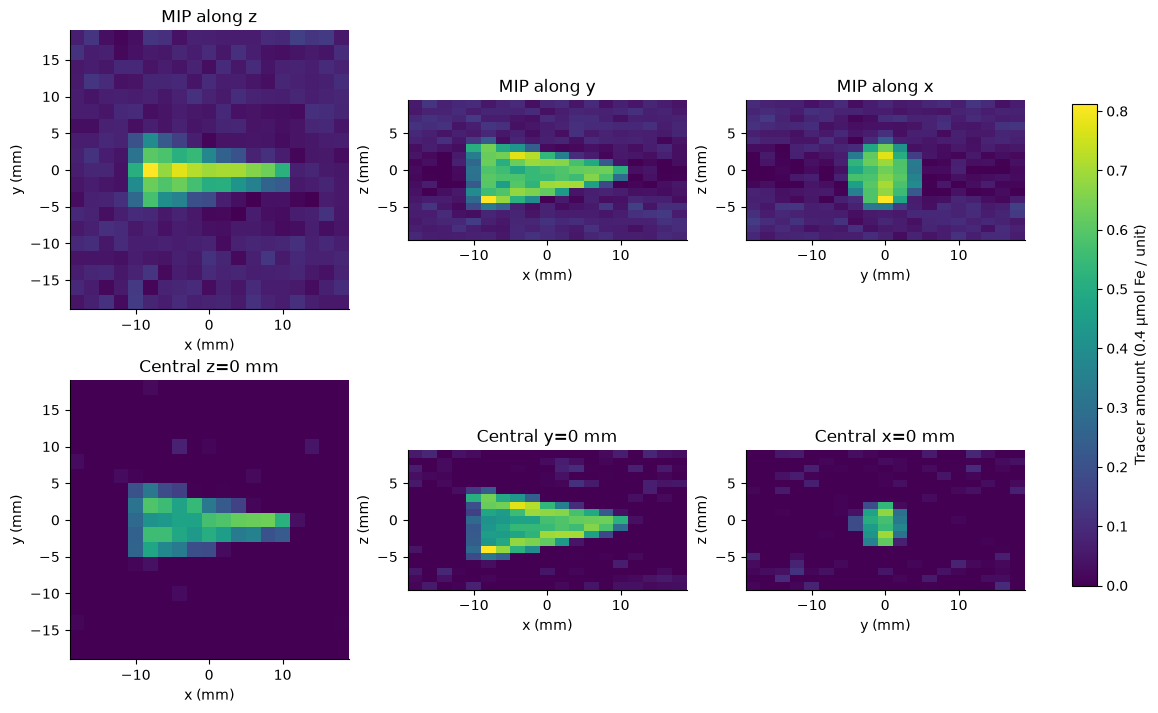

In [3]:
display(review_figures[0][1])
plt.close(review_figures[0][1])

### Independent original parity and complex data fidelity

The reference is the independently executed original method on the exact bound observations. The fresh estimate is computed above. All6859 coefficients and all7116 complex measured rows are included. The residual shows model/noise discrepancy; original agreement alone would not demonstrate physical accuracy. Dashed vertical separators identify receive-channel boundaries.


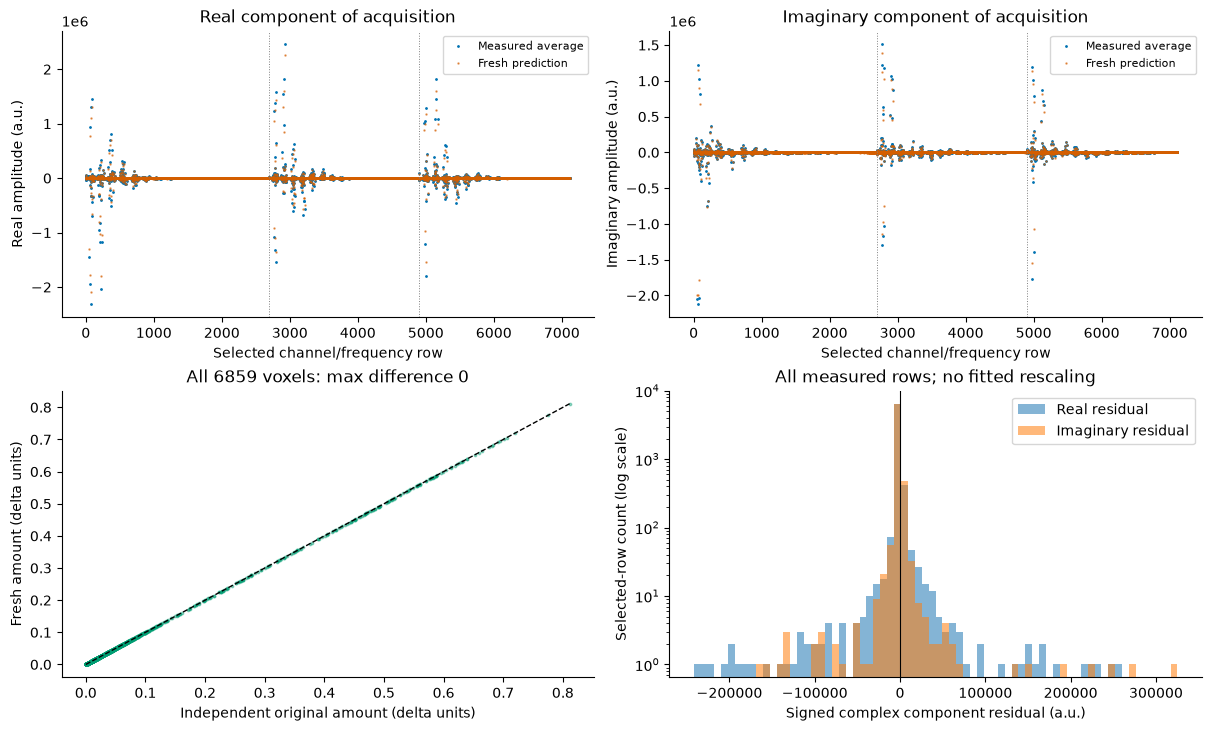

In [4]:
display(review_figures[1][1])
plt.close(review_figures[1][1])

### Finite sweeps and regularization

All1..10 sweep states and four damping choices were computed from the complete1000-cycle mean. Projection can make the forward residual nonmonotonic, so these plots do not claim monotone objective convergence. Image panels use a common full range. Parameter sensitivity is measured against the original selected estimator, not physical truth. The separate2-D SVD demo in the MDF source uses other observations and is not relabeled as a3-D benchmark comparison.


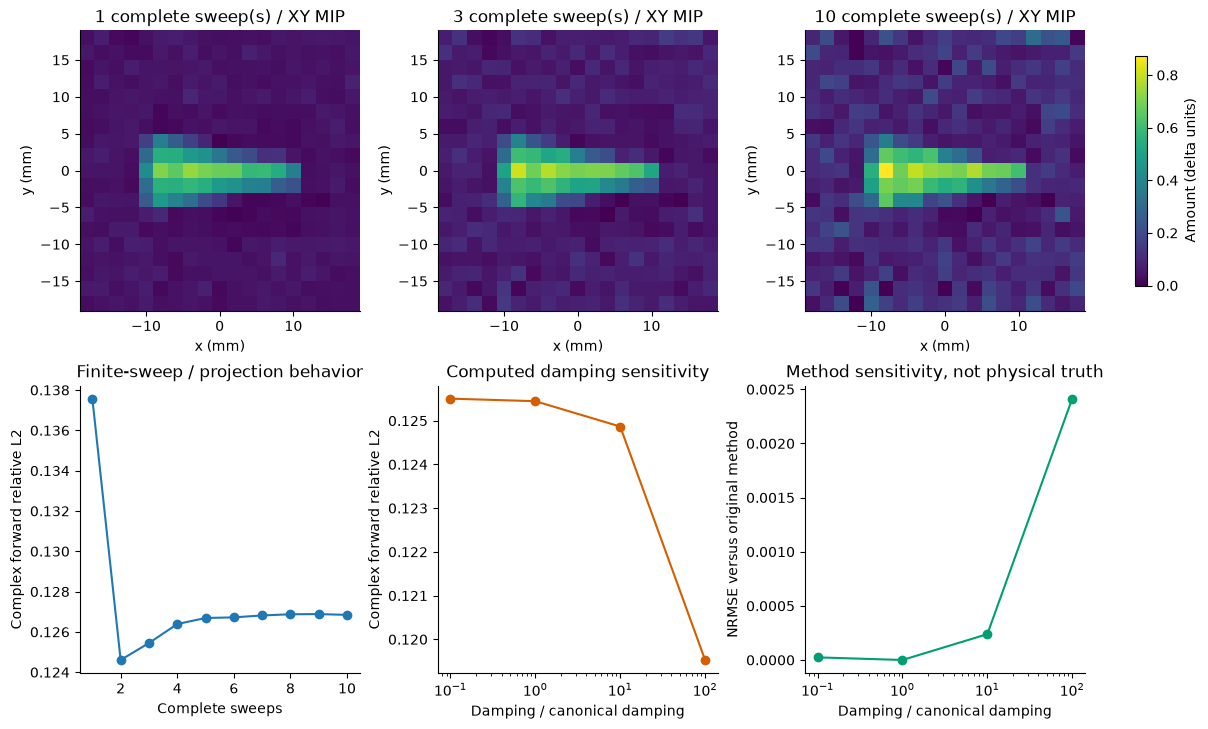

In [5]:
display(review_figures[2][1])
plt.close(review_figures[2][1])

### Acquired-cycle averaging and independent background controls

The1,10,100,1000 foreground-average diagnostics use the same complete spatial calibration and all1000 empty-bore background cycles. All four are computed; selected image panels show1,10,1000 while the error curve includes100. The no-measurement-background diagnostic deliberately omits only the observation subtraction and retains independent calibration subtraction. The full-range shared color scale exposes changes without independent image rescaling. Canonical data and output always use all1000+1000 cycles.


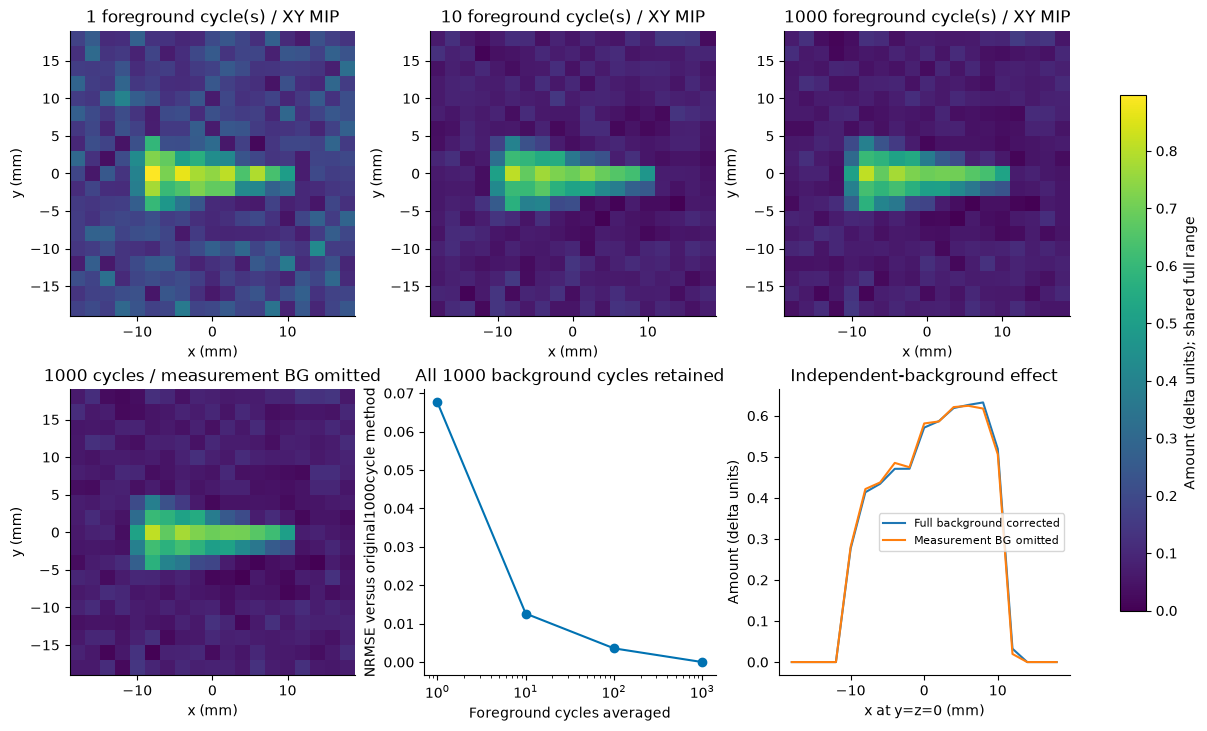

In [6]:
display(review_figures[3][1])
plt.close(review_figures[3][1])

## 6. Conclusion

### Result and limits

Fresh results agree with the independent original numerical estimator and satisfy the separately computed complex forward criterion. A visible3-D tracer shape is recovered, while finite calibration resolution, overscan sensitivity, background drift and finite-sweep bias remain. No CAD geometry, target volume, target concentration or hidden reconstruction was used as calibration. The effective linear model is tied to this particle/drive/receive calibration; absolute physiological accuracy is not established.

References: OpenMPIData, DOI10.1016/j.dib.2019.104971; MDF arXiv1602.06072v6. Data/native source and license provenance are fully indexed in test/validation.md.
